# Ordering in Cu–Pt from EMT with landau

In EMT, Cu and Pt mix strongly (about −80 meV/atom for the random alloy at $x = 1/2$), and the
ordered fcc superstructures are lower still.  This notebook lets the disordered solid solution
compete with three ordered compounds and has [landau](https://github.com/eisenforschung/landau)
work out where each one is stable.

| phase | structures | free energy |
|---|---|---|
| disordered fcc | pure Cu, Pt + SQS at $x = 1/4, 1/2, 3/4$ | quasi-harmonic (phonopy) per structure, Redlich–Kister in $x$, ideal configurational entropy |
| Cu$_3$Pt, CuPt, CuPt$_3$ | L1$_2$, L1$_0$, L1$_2$ | quasi-harmonic line compounds |

The ordering happens far below melting, so there is no liquid here.  EMT is not fitted to Cu–Pt;
the diagram illustrates the workflow, not the real alloy.

The notebook is self-contained: it builds every structure, computes all phonons with EMT and
writes every figure as SVG to `figures/`.  The first run takes about ten minutes on a laptop,
mostly for the phonons of the three 32-atom SQS; the force constants are cached in `cache/`, so
later runs take about a minute.

In [1]:
import os

os.environ.setdefault("OMP_NUM_THREADS", "1")  # numpy threads only slow down the many tiny fits below
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")

import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import phonopy
import structuretoolkit as stk
from ase import Atoms
from ase.build import bulk
from ase.calculators.emt import EMT
from ase.filters import FrechetCellFilter
from ase.optimize import BFGS
from phonopy import Phonopy
from phonopy.structure.atoms import PhonopyAtoms

from landau import PhonopyQuasiHarmonicPhase, Surface2DInterpolatingPhase
from landau.calculate import calc_phase_diagram
from landau.interpolate import CalphadSurface2DInterpolator, SplineFit
from landau.phases.quasiharmonic import EosExtrapolationWarning
from landau.plot import plot_excess_free_energy, plot_mu_phase_diagram, plot_phase_diagram
from matplotlib.colors import Normalize

warnings.filterwarnings("ignore", category=EosExtrapolationWarning)  # see Settings
# landau repairs a self-intersecting phase polygon on its own; no need to hear about each one
warnings.filterwarnings("ignore", message=".*produced an invalid polygon")

/home/pmrv/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/claude-1000/matplotlib-gi3grxlu because there was an issue with the default path (/home/pmrv/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


/home/pmrv/science/umich/projects/2026/11_MMM_LANDAU_POSTER/figures/CuPt/.pixi/envs/default/lib/python3.12/site-packages/structuretoolkit/analyse/neighbors.py:667: SyntaxWarning: invalid escape sequence '\p'
  Y^m_l(\theta,\phi) = \sqrt{\frac{2l+1}{4\pi} \frac{(l-m)!}{(l+m)!}}


## Settings

Every structure is sampled over the same window of linear strains around its relaxed cell.  EMT's
quasi-harmonic thermal expansion runs away at high temperature (Pt turns dynamically unstable
beyond about +4% strain), so above the temperature where a phase's free-energy minimum leaves the
window, landau clamps the volume to its edge and warns with `EosExtrapolationWarning`.  Using
one window for all structures keeps that error comparable between the phases.

In [2]:
A, B = "Cu", "Pt"
LATTICE_GUESS = {"Cu": 3.61, "Pt": 3.92}
T_MIN, T_MAX = 200, 700

STRAINS = np.linspace(-0.02, 0.03, 6)
SQS_REPEAT = 2  # SQS cells are SQS_REPEAT^3 conventional fcc cells (32 atoms)
CACHE = Path("cache") / f"strain{STRAINS[0]:+.2f}{STRAINS[-1]:+.2f}x{len(STRAINS)}_sqs{SQS_REPEAT}"
CACHE.mkdir(parents=True, exist_ok=True)
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)


def save(fig, name):
    # colour fields are drawn as meshes of thousands of cells; embed those as images, keep the rest vector
    for ax in fig.axes:
        for artist in ax.collections:
            if type(artist).__name__ == "QuadMesh":
                artist.set_rasterized(True)
    fig.savefig(FIGURES / f"{name}.svg", bbox_inches="tight", dpi=200)

## Structures

Ordered phases use the 4-atom conventional fcc cell, the disordered alloy uses 32-atom SQS from
`structuretoolkit`.  $x$ is the Pt fraction.

In [3]:
def fcc(element, a=None):
    return bulk(element, "fcc", a=a or LATTICE_GUESS[element], cubic=True)


def lattice(x):
    return (1 - x) * LATTICE_GUESS[A] + x * LATTICE_GUESS[B]


def ordered(n_B):
    """L1_2 Cu3Pt (n_B = 1), L1_0 CuPt (2) or L1_2 CuPt3 (3) in the conventional cell."""
    atoms = fcc(A, lattice(n_B / 4))
    symbols = atoms.get_chemical_symbols()
    for i in range(n_B):  # sites 0 and 1 share a (100) plane, so n_B = 2 gives the layered L1_0
        symbols[i] = B
    atoms.set_chemical_symbols(symbols)
    return atoms


def sqs(x, seed=42):
    n = 4 * SQS_REPEAT**3
    n_B = round(x * n)
    result = stk.build.sqs_structures(
        fcc(A, lattice(x)), {A: n - n_B, B: n_B},
        supercell=(SQS_REPEAT,) * 3,
        shell_weights={1: 1.0, 2: 0.5, 3: 0.25},
        iterations=500_000,
        max_results_per_objective=1,
        num_threads=1,
        seed=seed,
    )
    return result.best().atoms()

## Quasi-harmonic free energies

Each structure is relaxed (cell and positions), strained, relaxed again at fixed cell, and
handed to phonopy for finite-displacement force constants with EMT.  All force constants come
from cells of the same size (32 atoms), so the small-cell error largely cancels between phases.
The three acoustic modes at Γ are excluded from the mode sums: they come out at ±1e-6 THz
instead of zero and would otherwise add a random $k_BT \ln(h\nu/k_BT)$ to every structure.

landau's `PhonopyQuasiHarmonicPhase` takes the phonopy objects as they are and minimises
$E(V) + F_\mathrm{vib}(V, T)$ at whatever temperature it is asked for.

In [4]:
def relax(atoms, cell=True, fmax=1e-3):
    atoms = atoms.copy()
    atoms.calc = EMT()
    BFGS(FrechetCellFilter(atoms) if cell else atoms, logfile=None).run(fmax=fmax, steps=500)
    return atoms


def emt_forces(cell):
    atoms = Atoms(cell.symbols, cell=cell.cell, scaled_positions=cell.scaled_positions, pbc=True)
    atoms.calc = EMT()
    return atoms.get_forces()


def compute_phonons(atoms, path):
    repeat = max(1, round((4 * SQS_REPEAT**3 / len(atoms)) ** (1 / 3)))
    unitcell = PhonopyAtoms(
        symbols=atoms.get_chemical_symbols(), cell=atoms.cell[:], scaled_positions=atoms.get_scaled_positions()
    )
    ph = Phonopy(unitcell, supercell_matrix=np.eye(3) * repeat, primitive_matrix="auto")
    ph.generate_displacements(distance=0.01)
    ph.forces = [emt_forces(sc) for sc in ph.supercells_with_displacements]
    ph.produce_force_constants()
    ph.save(path, settings={"force_constants": True})


def load_phonons(path):
    ph = phonopy.load(path, log_level=0)
    ph.run_mesh(40.0)
    ph.run_thermal_properties(exclude_gamma_acoustic=True)
    return ph


def qha_phase(name, x, key, build):
    """Quasi-harmonic line phase for the structure from build(); cached under key."""
    energy_file = CACHE / f"{key}.json"
    if not energy_file.exists():
        relaxed = relax(build())
        energies = []
        for i, strain in enumerate(STRAINS):
            strained = relaxed.copy()
            strained.set_cell(relaxed.cell * (1 + strain), scale_atoms=True)
            strained = relax(strained, cell=False)
            energies.append(strained.get_potential_energy())
            compute_phonons(strained, CACHE / f"{key}_{i}.yaml")
        energy_file.write_text(json.dumps(energies))
    energies = json.loads(energy_file.read_text())
    phonopys = [load_phonons(CACHE / f"{key}_{i}.yaml") for i in range(len(STRAINS))]
    return PhonopyQuasiHarmonicPhase.from_phonopy(name, x, phonopys, energies)

## Phases

The disordered alloy is a `Surface2DInterpolatingPhase`: landau samples the free energies of the
pure elements and the three SQS on a temperature grid and fits one CALPHAD-style surface,

$$ F(x, T) = (1-x) F_\mathrm{Cu}(T) + x F_\mathrm{Pt}(T) + x(1-x) \sum_{v=0}^{2} L_v(T) (1-2x)^v - T S_\mathrm{ideal}(x), $$

with splines for the pure elements and quadratic polynomials in $T$ for the Redlich–Kister
parameters $L_v$.  The ordered compounds are fixed-composition line phases with no
configurational entropy.

In [5]:
pure = [qha_phase("fcc Cu", 0.0, A, lambda: fcc(A)), qha_phase("fcc Pt", 1.0, B, lambda: fcc(B))]
sqs_phases = [qha_phase(f"SQS x={x}", x, f"{A}{B}_sqs{int(x * 100)}", lambda: sqs(x)) for x in (0.25, 0.5, 0.75)]

solid = Surface2DInterpolatingPhase(
    "fcc",
    phases=[pure[0], *sqs_phases, pure[1]],
    add_entropy=True,
    surface_interpolator=CalphadSurface2DInterpolator(num_coeffs=3, coeff_poly_order=2, terminal_interpolator=SplineFit()),
    temperature_range=(0, T_MAX),
    num_temperature_samples=60,
)
compounds = [
    qha_phase(r"Cu$_3$Pt", 0.25, f"{A}{B}_L12_A3B", lambda: ordered(1)),
    qha_phase("CuPt", 0.50, f"{A}{B}_L10", lambda: ordered(2)),
    qha_phase(r"CuPt$_3$", 0.75, f"{A}{B}_L12_AB3", lambda: ordered(3)),
]
phases = [solid, *compounds]
COLORS = {"fcc": "#4a90d9", r"Cu$_3$Pt": "#4caf50", "CuPt": "#e5737a", r"CuPt$_3$": "#9575cd"}

## Phase diagram

`calc_phase_diagram` samples temperature and the chemical-potential difference
$\Delta\mu = \mu_\mathrm{Pt} - \mu_\mathrm{Cu}$, picks the phase with the lowest semi-grand
potential $\phi = f - \Delta\mu\, x$ at each point and refines every boundary it finds.  The
result is one table, from which landau draws both the concentration–temperature and the
chemical-potential–temperature diagram.

In [6]:
diagram = calc_phase_diagram(phases, Ts=np.linspace(T_MIN, T_MAX, 100), mu=200)

Each diagram comes in four variants: with or without the transition temperatures written on the
invariant lines, and with or without those lines drawn.  In the $\Delta\mu$–$T$ diagram every
two-phase region of the $x$–$T$ diagram collapses to a line, and the line compounds open up into
areas.

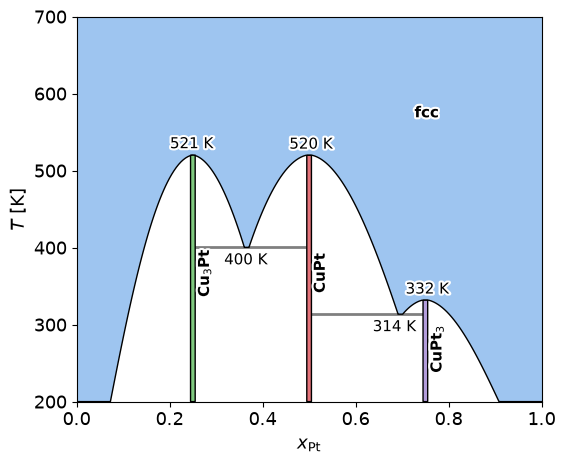

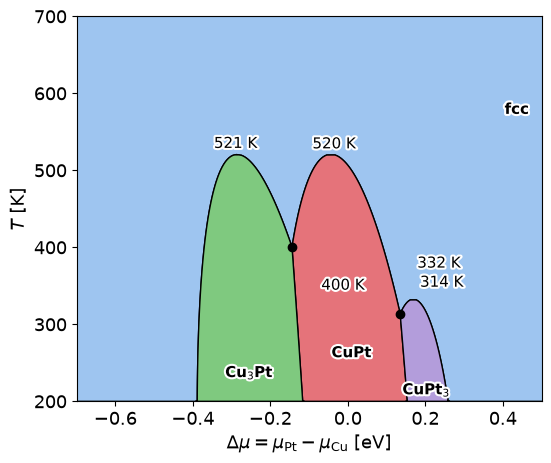

In [7]:
PASTEL = {"fcc": "#9ec5f0", r"Cu$_3$Pt": "#7fc97f", "CuPt": "#e5737a", r"CuPt$_3$": "#b39ddb"}
MU_RANGE = (-0.7, 0.5)  # eV; the ordered phases live well inside this window
plt.rcParams.update({"font.size": 13})


def finish(ax, kind):
    if kind == "mu":
        ax.set_xlim(*MU_RANGE)
        ax.set_xlabel(r"$\Delta\mu = \mu_\mathrm{Pt} - \mu_\mathrm{Cu}$ [eV]")
    else:
        ax.set_xlabel(r"$x_\mathrm{Pt}$")


PLOTS = {"cT": plot_phase_diagram, "muT": plot_mu_phase_diagram}
for kind, plot in PLOTS.items():
    for labels in (False, True):
        for lines in (False, True):
            fig, ax = plt.subplots(figsize=(6, 5))
            plot(diagram, ax=ax, element=B, color_override=PASTEL, transition_temperatures=labels, triplepoints=lines)
            finish(ax, "mu" if kind == "muT" else "c")
            save(fig, f"CuPt_{kind}_{'T' if labels else 'noT'}_{'lines' if lines else 'nolines'}")
            if not (labels and lines):
                plt.close(fig)

## Colour fields

Instead of one flat colour per phase, landau can fill every phase field with any numeric column
of the diagram table (`color_by`).  Each diagram can show the variable of the other: the $x$–$T$
diagram coloured by $\Delta\mu$, the $\Delta\mu$–$T$ diagram coloured by $x$.

Two more fields:

* the **formation free energy** `f_excess`, relative to the pure elements;
* the **stability margin**: how far the semi-grand potential of the runner-up phase lies above
  the stable one.  It is zero on every phase boundary and largest where a phase is most stable.
  landau's table does not contain it, so it is computed here from the phases themselves and added
  as a column.

In [8]:
def stability_margin(diagram, phases):
    """phi(runner-up) - phi(stable) in meV/atom for every stable row of the diagram."""
    stable = diagram["stable"].to_numpy() & np.isfinite(diagram["mu"].to_numpy(float))
    T, mu = diagram["T"].to_numpy(float), diagram["mu"].to_numpy(float)
    phi = np.full((len(phases), len(diagram)), np.inf)
    for i, phase in enumerate(phases):
        for t in np.unique(T[stable]):
            rows = stable & (T == t)
            phi[i, rows] = phase.semigrand_potential(t, mu[rows])
    own = np.array([[p.name for p in phases].index(n) for n in diagram["phase"]])
    rows = np.arange(len(diagram))
    phi_own = phi[own, rows].copy()
    phi[own, rows] = np.inf
    with np.errstate(invalid="ignore"):  # rows that are not stable carry inf - inf
        margin = (phi.min(axis=0) - phi_own) * 1e3
    return np.where(stable, margin, np.nan)


diagram["margin"] = stability_margin(diagram, phases)

# landau 1.17.0 leaves f_excess at 0 on the boundary points its Clausius-Clapeyron refiner adds;
# recompute it from f, relative to the free energies of pure Cu and Pt (identical elsewhere)
T, x = diagram["T"].to_numpy(float), diagram["c"].to_numpy(float)
diagram["f_excess"] = diagram["f"] - (1 - x) * solid.free_energy(T, 0.0) - x * solid.free_energy(T, 1.0)

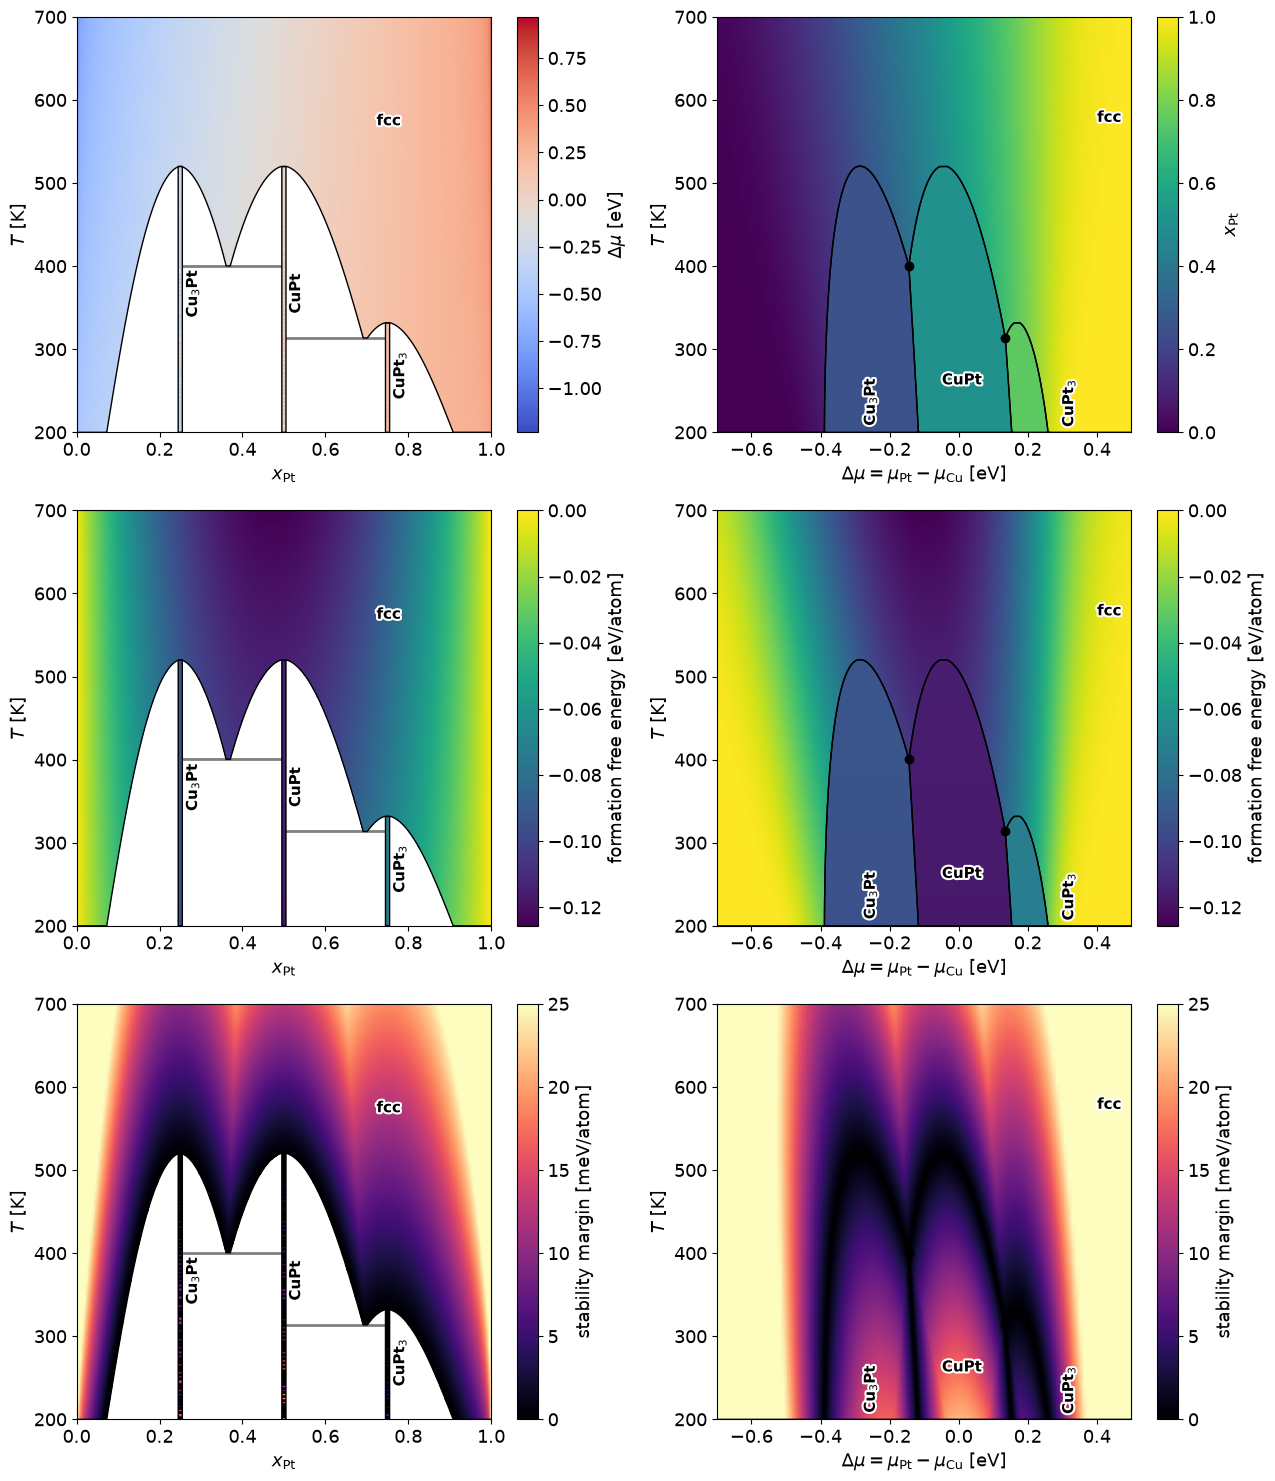

In [9]:
FIELDS = [  # (diagram, column, colour bar label, colour map, colour range)
    ("cT", "mu", r"$\Delta\mu$ [eV]", "coolwarm", None),
    ("muT", "c", r"$x_\mathrm{Pt}$", "viridis", None),
    ("cT", "f_excess", "formation free energy [eV/atom]", "viridis", None),
    ("muT", "f_excess", "formation free energy [eV/atom]", "viridis", None),
    ("cT", "margin", "stability margin [meV/atom]", "magma", Normalize(0, 25)),
    ("muT", "margin", "stability margin [meV/atom]", "magma", Normalize(0, 25)),
]
fig_all, axes = plt.subplots(3, 2, figsize=(13, 15))
for target, (kind, column, label, cmap, norm) in zip(axes.flat, FIELDS):
    for ax in (target, plt.subplots(figsize=(6.8, 5))[1]):
        PLOTS[kind](diagram, ax=ax, element=B, color_by=column, cmap=cmap, norm=norm, triplepoints=True)
        finish(ax, "mu" if kind == "muT" else "c")
        ax.figure.axes[-1].set_ylabel(label)
        if ax is not target:
            save(ax.figure, f"CuPt_{kind}_by_{column}")
            plt.close(ax.figure)
fig_all.tight_layout()
save(fig_all, "CuPt_colour_fields")